# 02 · Pipeline predictivo y visualización
**Tarea:** aprendizaje supervisado de regresión.
**Variable objetivo:** `beneficio_neto_musd`, beneficio económico neto sintético expresado en millones de USD.
**Modelo:** Ridge Regression, una regresión lineal con regularización L2 que ayuda a limitar coeficientes inestables.
**Advertencia:** los datos fueron simulados mediante una fórmula didáctica y ruido, no son observaciones científicas reales. Esta actividad ilustra técnicas de ML, no la factibilidad técnica o financiera de la minería espacial.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

GITHUB_USUARIO = "TU_USUARIO"  # Editar si ejecutas en Colab sin clonar
REPOSITORIO = "ml-mineria-asteroides"
archivo = Path("data/asteroides_sinteticos.csv")
if not archivo.exists():
    archivo = Path("../data/asteroides_sinteticos.csv")
if archivo.exists():
    df = pd.read_csv(archivo)
else:
    if GITHUB_USUARIO == "TU_USUARIO":
        raise FileNotFoundError("Clona el repositorio, sube el CSV a Colab, o configura GITHUB_USUARIO.")
    df = pd.read_csv(f"https://raw.githubusercontent.com/{GITHUB_USUARIO}/{REPOSITORIO}/main/data/asteroides_sinteticos.csv")
display(df.head())
print('Registros:',len(df),'| Valores faltantes:',int(df.isna().sum().sum()))

,asteroide_id,distancia_millones_km,masa_millones_ton,concentracion_metal_pct,costo_mision_musd,riesgo_operacional,beneficio_neto_musd
0,AST-001,91.72,13.09,65.03,158.71,0.214,-19.85
1,AST-002,57.20,20.31,18.40,311.64,0.291,-190.97
2,AST-003,100.44,27.02,57.22,136.90,0.424,276.56
3,AST-004,83.83,38.29,20.93,111.20,0.237,518.90
4,AST-005,21.70,12.53,26.14,175.48,0.129,-57.55


Registros: 220 | Valores faltantes: 0


## 1. Variables y partición de datos
**X:** distancia, masa, concentración metálica, costo de misión y riesgo operacional.
**y:** beneficio neto sintético.
Usamos 80 % de datos para entrenamiento y 20 % para prueba; el escalado se ajusta solo en entrenamiento para evitar fuga de información.

In [2]:
columnas = ["distancia_millones_km", "masa_millones_ton", "concentracion_metal_pct", "costo_mision_musd", "riesgo_operacional"]
X, y = df[columnas], df["beneficio_neto_musd"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)
modelo = Pipeline([("escalado",StandardScaler()),("regresion",Ridge(alpha=1.0))])
modelo.fit(X_train,y_train)
pred = modelo.predict(X_test)
mae = mean_absolute_error(y_test,pred)
rmse = np.sqrt(mean_squared_error(y_test,pred))
r2 = r2_score(y_test,pred)
print(f"MAE = {mae:.2f} MUSD")
print(f"RMSE = {rmse:.2f} MUSD")
print(f"R² = {r2:.3f}")
assert len(pred)==len(y_test)
cv = cross_val_score(modelo, X_train, y_train, cv=5, scoring="r2")
print(f"R² validación cruzada (solo train): {cv.mean():.3f} ± {cv.std():.3f}")

MAE = 28.74 MUSD
RMSE = 34.95 MUSD
R² = 0.985
R² validación cruzada (solo train): 0.986 ± 0.001


## 2. Gráficos interpretativos
**Gráfico 1:** observaciones vs predicciones; una buena predicción se aproxima a la diagonal.
**Gráfico 2:** importancia direccional mediante coeficientes de Ridge tras estandarizar predictores; muestran asociaciones en los datos simulados, no causalidad.

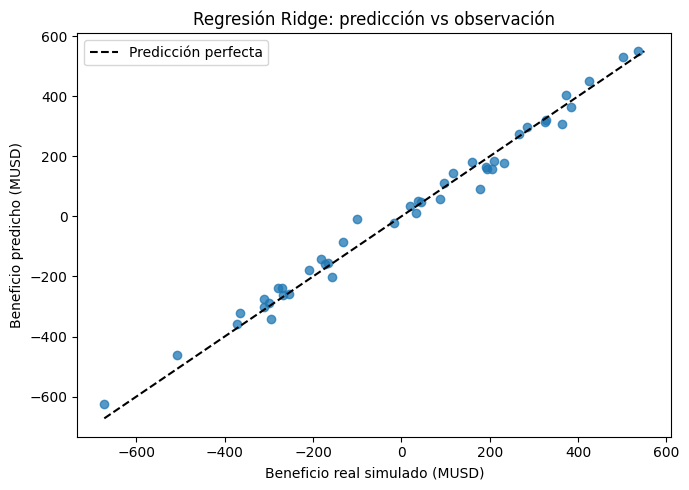

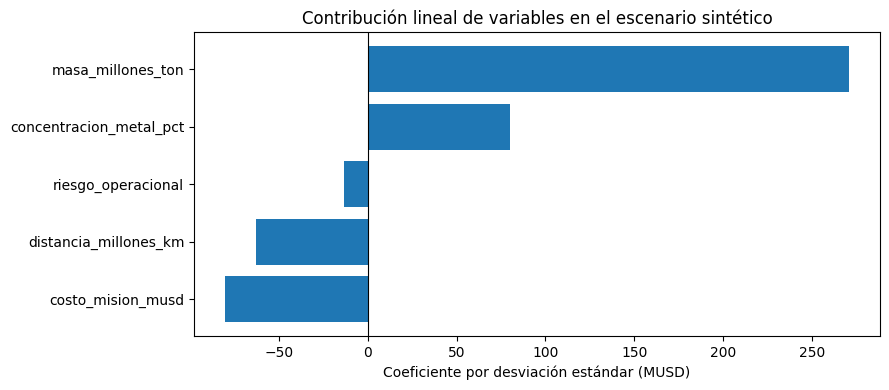

In [3]:
fig,ax=plt.subplots(figsize=(7,5))
ax.scatter(y_test,pred,alpha=.75)
lo=min(y_test.min(),pred.min()); hi=max(y_test.max(),pred.max())
ax.plot([lo,hi],[lo,hi],'--',color='black',label='Predicción perfecta')
ax.set(xlabel='Beneficio real simulado (MUSD)', ylabel='Beneficio predicho (MUSD)',title='Regresión Ridge: predicción vs observación')
ax.legend(); plt.tight_layout(); plt.show()

coefs = pd.Series(modelo.named_steps['regresion'].coef_, index=columnas).sort_values()
fig,ax=plt.subplots(figsize=(9,4))
ax.barh(coefs.index,coefs.values)
ax.axvline(0,color='black',linewidth=.8)
ax.set(xlabel='Coeficiente por desviación estándar (MUSD)',title='Contribución lineal de variables en el escenario sintético')
plt.tight_layout(); plt.show()

## 3. Ejemplo de inferencia y conclusiones
El pipeline permite estimar el beneficio neto sintético de un nuevo asteroide. Para evaluar decisiones reales serían necesarios datos observacionales, incertidumbre de recursos, costos de transporte, avances de ingeniería, valoración de materiales y validación independiente.

In [4]:
nuevo = pd.DataFrame([{'distancia_millones_km':42.0,'masa_millones_ton':23.0,
'concentracion_metal_pct':58.0,'costo_mision_musd':210.0,'riesgo_operacional':0.18}])
estimacion = modelo.predict(nuevo)[0]
print(f"Beneficio neto sintético predicho: {estimacion:.2f} millones USD")
print('Interpretación: resultado académico, no evaluación comercial ni científica real.')

Beneficio neto sintético predicho: 240.81 millones USD
Interpretación: resultado académico, no evaluación comercial ni científica real.
